# Diplomatura en ciencia de datos, aprendizaje automático y sus aplicaciones

## Edición 2026 - Optativa: Aprendizaje por Refuerzo

Profesores: Jorge Palombarini y Juan Barsce

---

# Exploración de datos

Autor: Gonzalo Perez Paina

Enlaces:
- [Repositorio de la materia](https://github.com/DiploDatos/AprendizajePorRefuerzos/)
- [Consigna del Trabajo Práctico](https://github.com/DiploDatos/AprendizajePorRefuerzos/blob/master/2026/tp/CONSIGNA.md)

## Introducción

### Carga de los datos

La [guía](https://github.com/DiploDatos/AprendizajePorRefuerzos/blob/master/2026/tp/GUIA.md#6-calidad-de-los-logs) para el desarrollo del trabajo práctico indica que la carga se puede utilizar el siguiente fragmento de código:
```python
from protocolo.datos import load_train, load_test, split_by_user, num_items

dataset = "netflix"
n_items = num_items(dataset)
train_all = load_train(dataset)          # list[User]
train, val = split_by_user(train_all)    # 90 % / 10 % de los usuarios, por grupo
test = load_test(dataset)

u = train[0]
print(u.user_id, u.group, len(u.items), u.items[:5], u.ratings[:5])
```

Cada `User` tiene `group`, `items` y `ratings` alineados: `ratings[k]` es la valoración de `items[k]`.

| | Train | Test |
|---|---|---|
| Usuarios | 16.000 (2.000 por grupo) | 1.600 (200 por grupo) |
| Ítems por usuario | entre 25 y 200, sin repetir | todos los del catálogo |
| Orden | el registrado | el del catálogo (0, 1, 2, …) |
| Para qué | entrenar y validar | sólo la evaluación final |

Train y test tienen usuarios **distintos**. Un modelo no puede memorizar a un usuario de test: tiene que generalizar a partir de su grupo o de lo que observa durante la sesión.

`split_by_user` separa usuarios, no interacciones. Si se separaran interacciones de un mismo usuario entre train y validación, el modelo vería en train parte de los gustos que después se le pide adivinar, y la validación daría mejor de lo que es.

### Exploración de los datos

Antes de modelar, hay que entender cómo se registraron los datos. En RL offline, **la política que generó los logs determina qué se puede aprender de ellos**. Por ejemplo:

- Si los logs vienen de un buen recomendador, los ítems que aparecen mucho son probablemente buenos.
- Si vienen del azar, aparecer mucho no dice nada.

Este fragmento arma una tabla con una fila por interacción y responde las dos preguntas centrales:

```python
import pandas as pd

rows = [(u.group, pos, item, r)
        for u in train for pos, (item, r) in enumerate(zip(u.items, u.ratings))]
df = pd.DataFrame(rows, columns=["group", "pos", "item", "rating"])

# ¿El rating medio cambia según la posición en la trayectoria?
print(df.groupby(pd.cut(df.pos, [0, 10, 25, 50, 100, 200], right=False), observed=True).rating.mean())

# ¿Los ítems que más aparecen son los mejor valorados?
by_item = df.groupby("item").rating.agg(["mean", "count"])
print(by_item.corr())
```

## Consigna de exploración

Completar la exploración con:

- distribución de ratings, global y por grupo;
- cantidad de ítems por usuario;
- qué tan distintos son los grupos, por ejemplo con la correlación entre los ratings medios por ítem de cada par de grupos.

Anotar las conclusiones: se van a necesitar para interpretar los resultados de las secciones 4 a 6.

**Los IDs de test no están en orden de consumo.** Un usuario de test tiene ratings para los ítems 0, 1, 2, …, 751, en ese orden, porque así se guardaron, no porque los haya visto en ese orden. Predecir "el siguiente ID" del JSON de test no mide nada. Por eso el TP se evalúa con sesiones simuladas, no con predicción del siguiente ítem.

## Acceso al dataset y módulos Python

Las siguientes celdas que permiten trabajar con los datos y módulos Python desde el repositorio de GitHub se elaboraron con ayuda de Claude.

In [1]:
import os, sys, importlib
REPO = "DiploDatos/AprendizajePorRefuerzos"

In [2]:
RAIZ = "/content/" + REPO.split("/")[1]          # raíz del repo (clone / pull)
TRABAJO = os.path.join(RAIZ, "2026", "tp")       # directorio de trabajo

if not os.path.exists(RAIZ):
    !git clone -q https://github.com/{REPO}.git {RAIZ}
else:
    !git -C {RAIZ} pull -q

%cd {TRABAJO}
if os.path.exists("requirements.txt"):
    !pip install -q -r requirements.txt
sys.path.insert(0, TRABAJO)                      # para "import protocolo..."

# Parche: el autoreload de IPython en Colab todavía importa 'imp' (eliminado en Python 3.12+)
sys.modules.setdefault("imp", importlib)
%load_ext autoreload
%autoreload 2

/content/AprendizajePorRefuerzos/2026/tp


### Carga y exploración inicial

In [3]:
import pandas as pd

netflix8_train_df = pd.read_pickle("data/train/netflix8_train.df")
netflix8_train_df.head()

,user_id,user_group,items,ratings
0,0,0,"[472, 97, 122, 654, 709, 467, 574, 544, 478, 3...","[4.0, 3.0, 4.0, 3.0, 5.0, 4.0, 2.0, 1.0, 4.0, ..."
1,1,0,"[431, 445, 367, 100, 743, 739, 263, 426, 321, ...","[3.0, 5.0, 5.0, 5.0, 5.0, 3.0, 1.0, 4.0, 5.0, ..."
2,2,0,"[224, 133, 227, 51, 230, 546, 57, 60, 743, 495...","[5.0, 4.0, 3.0, 5.0, 4.0, 3.0, 4.0, 5.0, 5.0, ..."
3,3,0,"[338, 80, 210, 618, 468, 320, 351, 411, 575, 2...","[3.0, 5.0, 3.0, 5.0, 2.0, 1.0, 4.0, 3.0, 3.0, ..."
4,4,0,"[510, 231, 708, 86, 514, 352, 233, 351, 415, 6...","[4.0, 2.0, 3.0, 4.0, 5.0, 4.0, 2.0, 4.0, 3.0, ..."


Cada usuario tiene su `user_id` y pertenece a un grupo `user_group`. Los usuarios realizan la valoración de una serie de `items` (lista) con un valor de `ratings` (lista). Siendo el largo de la lista `items` igual al de la lista `ratings`.

In [4]:
netflix8_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     16000 non-null  int64 
 1   user_group  16000 non-null  int64 
 2   items       16000 non-null  object
 3   ratings     16000 non-null  object
dtypes: int64(2), object(2)
memory usage: 500.1+ KB


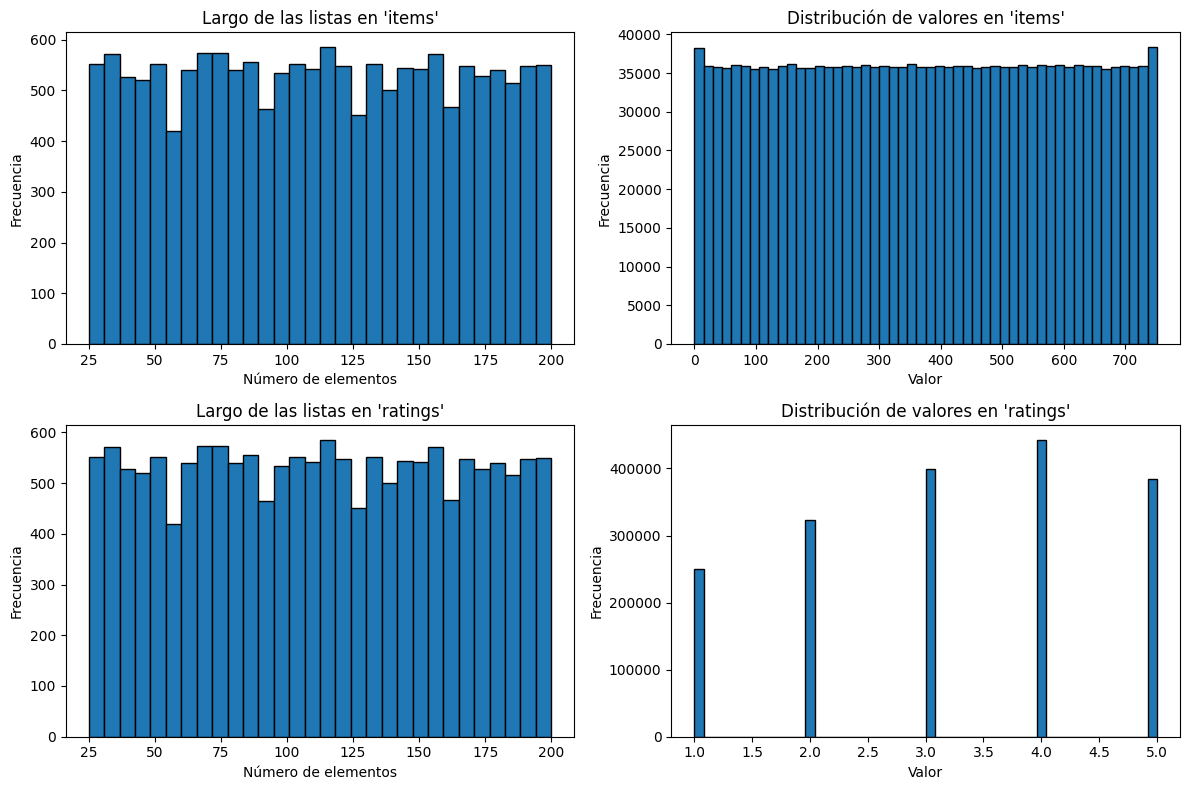

In [7]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def a_lista(x):
    """Normaliza cada celda a una lista de Python."""
    if isinstance(x, str):
        try:
            x = ast.literal_eval(x)          # "[1, 2, 3]" -> [1, 2, 3]
        except (ValueError, SyntaxError):
            return [x]
    if isinstance(x, (list, tuple, np.ndarray, pd.Series)):
        return list(x)
    return []                                # NaN / None / otros

columnas = ["items", "ratings"]

fig, axes = plt.subplots(len(columnas), 2, figsize=(12, 4 * len(columnas)))

for fila, col in zip(axes, columnas):
    ax_largo, ax_valores = fila
    serie = netflix8_train_df[col].apply(a_lista)

    # 1) Histograma del largo de cada lista
    largos = serie.str.len()
    ax_largo.hist(largos, bins=30, edgecolor="black")
    ax_largo.set(title=f"Largo de las listas en '{col}'",
                 xlabel="Número de elementos", ylabel="Frecuencia")

    # 2) Histograma de los valores contenidos en las listas
    valores = serie.explode().dropna()
    numericos = pd.to_numeric(valores, errors="coerce")

    if numericos.notna().all():
        ax_valores.hist(numericos, bins=50, edgecolor="black")
        ax_valores.set(xlabel="Valor")
    else:
        valores.astype(str).value_counts().head(30).plot.bar(ax=ax_valores)
        ax_valores.set(xlabel=col)
        ax_valores.tick_params(axis="x", rotation=90)

    ax_valores.set(title=f"Distribución de valores en '{col}'", ylabel="Frecuencia")

plt.tight_layout()
plt.show()

## Carga de datos y exploración según Guía

In [8]:
from protocolo.datos import load_train, load_test, split_by_user, num_items

dataset = "netflix"
n_items = num_items(dataset)
train_all = load_train(dataset)          # list[User]
train, val = split_by_user(train_all)    # 90 % / 10 % de los usuarios, por grupo
test = load_test(dataset)

u = train[0]
print(u.user_id, u.group, len(u.items), u.items[:5], u.ratings[:5])

0 0 77 [472  97 122 654 709] [4. 3. 4. 3. 5.]


Antes de modelar, hay que entender cómo se registraron los datos. En RL offline, **la política que generó los logs determina qué se puede aprender de ellos**. Por ejemplo:

- Si los logs vienen de un buen recomendador, los ítems que aparecen mucho son probablemente buenos.
- Si vienen del azar, aparecer mucho no dice nada.

El siguiente fragmento de código arma una tabla con una fila por interacción y responde las dos preguntas centrales:


1. ¿El rating medio cambia según la posición en la trayectoria?
2. ¿Los ítems que más aparecen son los mejor valorados?

In [9]:
import pandas as pd

rows = [(u.group, pos, item, r)
        for u in train for pos, (item, r) in enumerate(zip(u.items, u.ratings))]
df = pd.DataFrame(rows, columns=["group", "pos", "item", "rating"])

# ¿El rating medio cambia según la posición en la trayectoria?
print(df.groupby(pd.cut(df.pos, [0, 10, 25, 50, 100, 200], right=False), observed=True).rating.mean())

# ¿Los ítems que más aparecen son los mejor valorados?
by_item = df.groupby("item").rating.agg(["mean", "count"])
by_item.corr()

pos
[0, 10)       3.225611
[10, 25)      3.215125
[25, 50)      3.216467
[50, 100)     3.216799
[100, 200)    3.208684
Name: rating, dtype: float64


,mean,count
mean,1.000000,-0.041987
count,-0.041987,1.000000


In [10]:
#print(type(rows))
#print(len(rows))
#print(type(by_item))
#print(by_item)

***Respuestas:***
1. El valor medio resulta similar en todos los trabjos, por lo que el _"rating medio"_ NO cambia según la posición de la trayectoria. Esto indica que no hay una tendencia temporal.
2. A partir de los valores fuera de la diagonal principal (correlación cruzada), se establece que no hay relación lineal entre lo popular que es un ítem y lo bien valorado que está.




## Análisis de los datos

Para el análisis de los datos se utilizó código generado con Claude.

### Distribución de ratings, global y por grupo


Distribución global (proporción):
rating
1.0    0.139
2.0    0.180
3.0    0.222
4.0    0.246
5.0    0.213
Name: proportion, dtype: float64

Media: 3.215   Desvío: 1.337   Mediana: 3.0

Distribución por grupo (proporción, filas suman 1):
rating    1.0    2.0    3.0    4.0    5.0
group                                    
0       0.050  0.103  0.198  0.320  0.328
1       0.103  0.152  0.229  0.288  0.229
2       0.113  0.205  0.279  0.255  0.148
3       0.191  0.227  0.254  0.211  0.117
4       0.021  0.055  0.141  0.316  0.468
5       0.152  0.220  0.253  0.220  0.156
6       0.103  0.166  0.239  0.273  0.219
7       0.376  0.307  0.183  0.089  0.046

Resumen por grupo:
        mean    std  median   count
group                              
0      3.775  1.156     4.0  199661
1      3.387  1.271     4.0  203160
2      3.119  1.221     3.0  201552
3      2.837  1.282     3.0  202536
4      4.156  0.994     4.0  201156
5      3.008  1.293     3.0  204881
6      3.340  1.270     3.0  199666

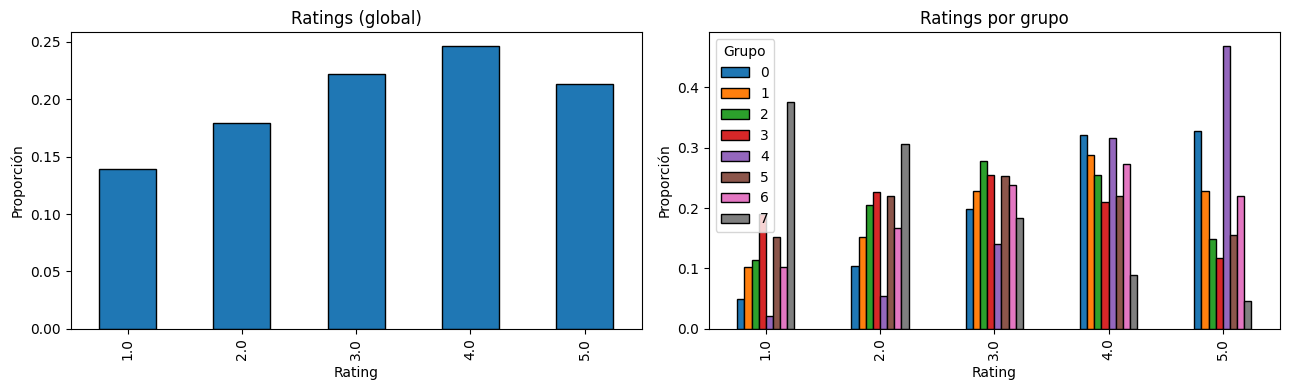

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- Distribución global ----------------
glob = df.rating.value_counts(normalize=True).sort_index()
print("Distribución global (proporción):")
print(glob.round(3))
print(f"\nMedia: {df.rating.mean():.3f}   Desvío: {df.rating.std():.3f}   "
      f"Mediana: {df.rating.median()}")

# ---------------- Distribución por grupo ----------------
dist_grupo = pd.crosstab(df.group, df.rating, normalize="index")
print("\nDistribución por grupo (proporción, filas suman 1):")
print(dist_grupo.round(3))

print("\nResumen por grupo:")
print(df.groupby("group").rating.agg(["mean", "std", "median", "count"]).round(3))

# ---------------- Gráficos ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

glob.plot.bar(ax=axes[0], edgecolor="black")
axes[0].set(title="Ratings (global)", xlabel="Rating", ylabel="Proporción")

dist_grupo.T.plot.bar(ax=axes[1], edgecolor="black")
axes[1].set(title="Ratings por grupo", xlabel="Rating", ylabel="Proporción")
axes[1].legend(title="Grupo")

plt.tight_layout()
plt.show()

El siguiente código genera los dos gráficos, uno al lado del otro. En ambos, los grupos van ordenados de mayor a menor rating medio y en el mismo orden vertical, así se pueden comparar fila por fila.

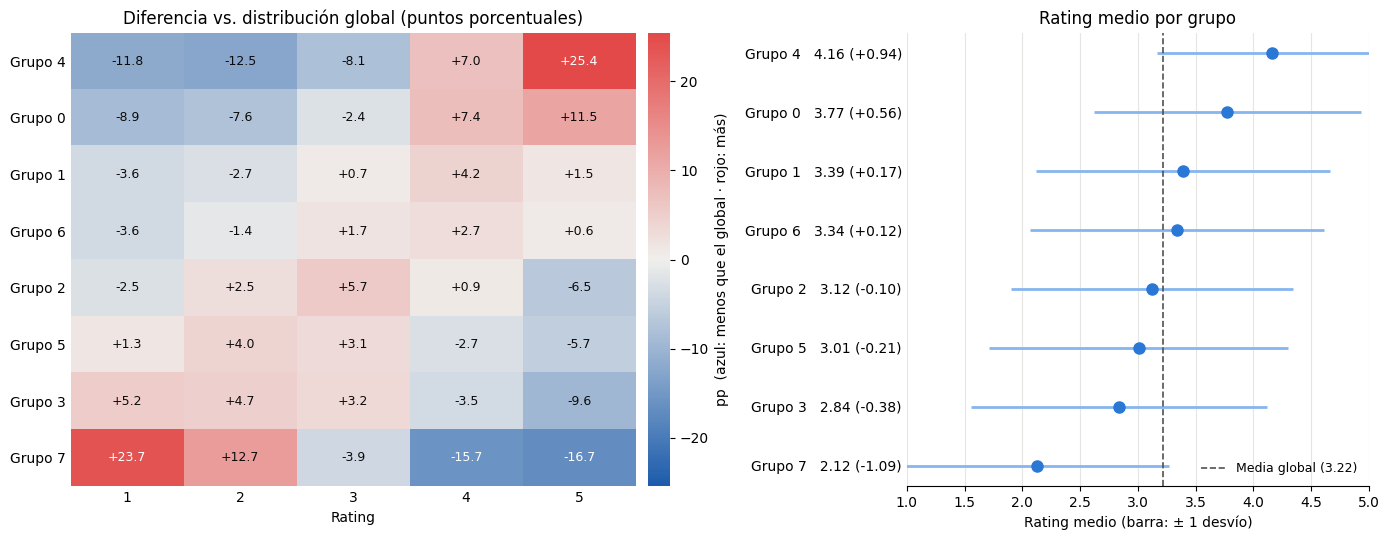

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# --- Orden de grupos: de mayor a menor rating medio (mismo orden en ambos gráficos) ---
resumen = df.groupby("group").rating.agg(["mean", "std"]).sort_values("mean", ascending=False)
orden = resumen.index
media_global = df.rating.mean()

# --- Diferencia de cada grupo vs. la distribución global, en puntos porcentuales ---
glob = df.rating.value_counts(normalize=True).sort_index()
dist_grupo = pd.crosstab(df.group, df.rating, normalize="index").loc[orden]
dif_pp = (dist_grupo - glob) * 100

# Escala divergente: azul = menos que el global, gris = igual, rojo = más que el global
cmap = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f0efec", "#e34948"])
lim = np.abs(dif_pp.values).max()
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, (ax_h, ax_p) = plt.subplots(1, 2, figsize=(14, 5.5),
                                 gridspec_kw={"width_ratios": [1.3, 1]})

# ---------------- 1) Mapa de calor de diferencias ----------------
im = ax_h.imshow(dif_pp.values, cmap=cmap, norm=norm, aspect="auto")
for i in range(dif_pp.shape[0]):
    for j in range(dif_pp.shape[1]):
        v = dif_pp.values[i, j]
        ax_h.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                  color="white" if abs(v) > 0.6 * lim else "#0b0b0b")
ax_h.set_xticks(range(dif_pp.shape[1]), [f"{c:g}" for c in dif_pp.columns])
ax_h.set_yticks(range(len(orden)), [f"Grupo {g}" for g in orden])
ax_h.set(xlabel="Rating", title="Diferencia vs. distribución global (puntos porcentuales)")
ax_h.tick_params(length=0)
for s in ax_h.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax_h, fraction=0.04, pad=0.02)
cb.set_label("pp  (azul: menos que el global · rojo: más)")
cb.outline.set_visible(False)

# ---------------- 2) Media ± desvío por grupo ----------------
y = np.arange(len(orden))
ax_p.errorbar(resumen["mean"], y, xerr=resumen["std"], fmt="o", color="#2a78d6",
              ecolor="#86b6ef", elinewidth=2, capsize=0, markersize=8)
ax_p.axvline(media_global, color="#52514e", linestyle="--", linewidth=1.2,
             label=f"Media global ({media_global:.2f})")
etiquetas = [f"Grupo {g}   {m:.2f} ({m - media_global:+.2f})"
             for g, m in zip(orden, resumen["mean"])]
ax_p.set_yticks(y, etiquetas)
ax_p.legend(loc="lower right", frameon=False, fontsize=9)
ax_p.invert_yaxis()                               # mismo orden vertical que el mapa de calor
ax_p.set_xlim(1, 5)
ax_p.set(xlabel="Rating medio (barra: ± 1 desvío)", title="Rating medio por grupo")
ax_p.grid(axis="x", color="#e6e5e1", linewidth=0.8)
ax_p.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax_p.spines[s].set_visible(False)
ax_p.tick_params(axis="y", length=0)

plt.tight_layout()
plt.show()

- **Mapa de calor (izquierda):** cada celda muestra cuántos puntos porcentuales se aparta el grupo de la distribución global para ese rating. Rojo significa que el grupo da ese rating más que el promedio, y azul que lo da menos. Como las filas están ordenadas por media, se forma una diagonal: los grupos generosos (4 y 0) son rojos a la derecha y azules a la izquierda, y el grupo 7 es lo contrario. Los grupos 1, 6, 2 y 5 quedan casi en gris, cerca del comportamiento global. El color está centrado exactamente en 0, así que el gris siempre significa "igual al global".
- **Media por grupo (derecha):** cada etiqueta muestra la media del grupo y su diferencia con la media global. Por ejemplo, el grupo 7 está 1,1 puntos por debajo y el grupo 4, 0,93 por encima. La barra de ± 1 desvío indica que, aun así, las distribuciones se solapan bastante. Los grupos se diferencian en la tendencia, no en que uno dé siempre notas altas y otro siempre bajas.

### Cantidad de ítems por usuario



Ítems por usuario (global):
count    14400.0
mean       112.2
std         50.7
min         25.0
5%          33.0
25%         69.0
50%        112.0
75%        156.0
95%        192.0
99%        199.0
max        200.0
Name: n_items, dtype: float64

Ítems por usuario, por grupo:
        count   mean   std   min    50%    max
group                                         
0      1800.0  110.9  50.1  25.0  109.0  200.0
1      1800.0  112.9  50.1  25.0  112.0  200.0
2      1800.0  112.0  50.8  25.0  114.0  200.0
3      1800.0  112.5  50.6  25.0  112.0  200.0
4      1800.0  111.8  50.9  25.0  111.0  200.0
5      1800.0  113.8  51.4  25.0  114.0  200.0
6      1800.0  110.9  50.9  25.0  111.5  200.0
7      1800.0  113.0  50.5  25.0  112.0  200.0

Longitudes más frecuentes:
n_items
155    110
77     103
147    102
65     101
160     99
Name: count, dtype: int64

El 10 % de usuarios con más ítems aporta el 17.1% de las interacciones


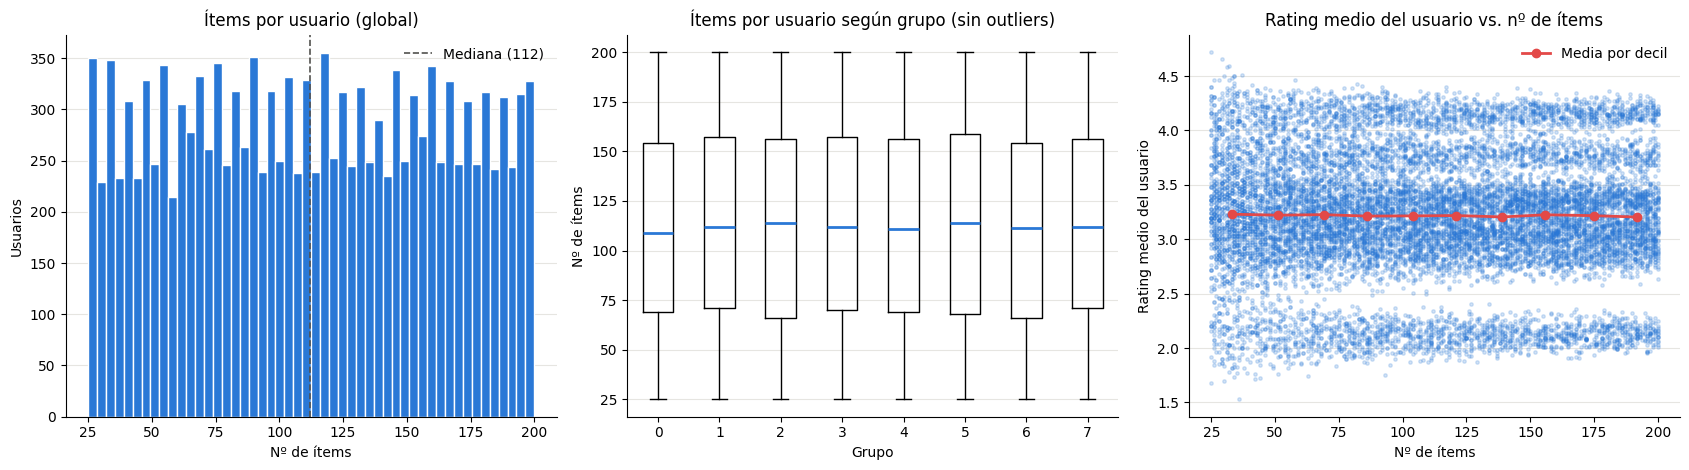

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Una fila por usuario
usuarios = pd.DataFrame({
    "user_id": [u.user_id for u in train],
    "group":   [u.group for u in train],
    "n_items": [len(u.items) for u in train],
    "rating_medio": [np.mean(u.ratings) for u in train],
})

# ---------------- Estadísticas ----------------
pct = [.05, .25, .5, .75, .95, .99]
print("Ítems por usuario (global):")
print(usuarios.n_items.describe(percentiles=pct).round(1))
print("\nÍtems por usuario, por grupo:")
print(usuarios.groupby("group").n_items.describe(percentiles=[.5]).round(1))

# ¿Hay valores "tope"? (indicio de trayectorias recortadas a una longitud fija)
print("\nLongitudes más frecuentes:")
print(usuarios.n_items.value_counts().head(5))

# Peso de los usuarios largos: qué % de las interacciones aportan
orden = usuarios.n_items.sort_values(ascending=False)
top10 = orden.head(int(len(orden) * 0.10)).sum() / orden.sum()
print(f"\nEl 10 % de usuarios con más ítems aporta el {top10:.1%} de las interacciones")

# ---------------- Gráficos ----------------
grupos = sorted(usuarios.group.unique())
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# 1) Histograma global
axes[0].hist(usuarios.n_items, bins=50, color="#2a78d6", edgecolor="white")
axes[0].axvline(usuarios.n_items.median(), color="#52514e", ls="--", lw=1.2,
                label=f"Mediana ({usuarios.n_items.median():.0f})")
axes[0].set(title="Ítems por usuario (global)", xlabel="Nº de ítems", ylabel="Usuarios")
axes[0].legend(frameon=False)

# 2) Distribución por grupo (boxplot)
axes[1].boxplot([usuarios.loc[usuarios.group == g, "n_items"] for g in grupos],
                tick_labels=[str(g) for g in grupos], showfliers=False,
                medianprops={"color": "#2a78d6", "lw": 2})
axes[1].set(title="Ítems por usuario según grupo (sin outliers)",
            xlabel="Grupo", ylabel="Nº de ítems")

# 3) ¿Los usuarios con más ítems valoran distinto?
axes[2].scatter(usuarios.n_items, usuarios.rating_medio, s=6, alpha=0.2, color="#2a78d6")
tramos = pd.qcut(usuarios.n_items, 10, duplicates="drop")
prom = usuarios.groupby(tramos, observed=True).agg(x=("n_items", "median"),
                                                  y=("rating_medio", "mean"))
axes[2].plot(prom.x, prom.y, color="#e34948", lw=2, marker="o", label="Media por decil")
axes[2].set(title="Rating medio del usuario vs. nº de ítems",
            xlabel="Nº de ítems", ylabel="Rating medio del usuario")
axes[2].legend(frameon=False)

for ax in axes:
    ax.grid(axis="y", color="#e6e5e1", lw=0.8)
    ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

plt.tight_layout()
plt.show()

### Qué tan distintos son los grupos, por ejemplo con la correlación entre los ratings medios por ítem de cada par de grupos.

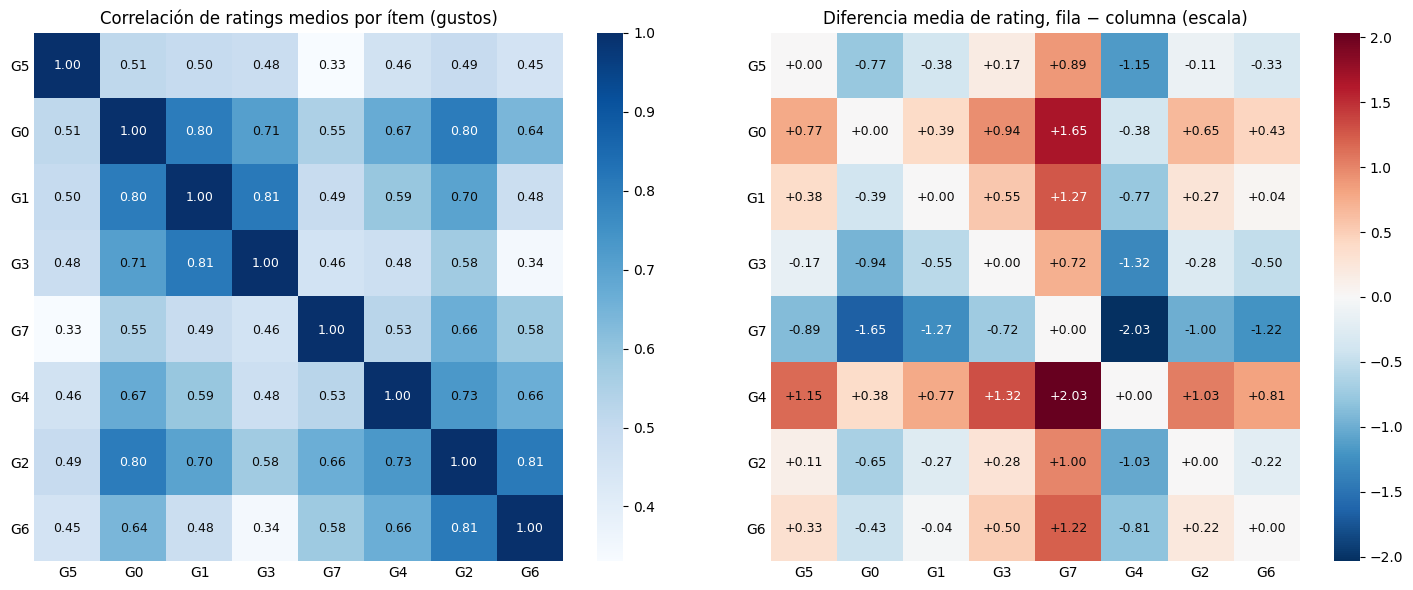

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

MIN_COUNT = 20   # mínimo de ratings de un ítem en un grupo para usar su media

# Matriz ítems × grupos con el rating medio
s = df.groupby(["item", "group"]).rating.agg(["mean", "count"])
M = s["mean"].where(s["count"] >= MIN_COUNT).unstack("group")

corr = M.corr()                                                                 # gustos
escala = pd.DataFrame({a: {b: (M[a] - M[b]).mean() for b in M} for a in M}).T  # generosidad

# Ordenar los grupos por similitud de gustos
orden = M.columns[leaves_list(linkage(squareform(1 - corr.values, checks=False), "average"))]

lim = np.abs(escala.values).max()
paneles = [
    ("Correlación de ratings medios por ítem (gustos)", corr, "Blues", corr.values.min(), 1, "{:.2f}"),
    ("Diferencia media de rating, fila − columna (escala)", escala, "RdBu_r", -lim, lim, "{:+.2f}"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (titulo, m, cmap, vmin, vmax, fmt) in zip(axes, paneles):
    m = m.loc[orden, orden]
    im = ax.imshow(m.values, cmap=cmap, vmin=vmin, vmax=vmax)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.values[i, j]
            c = im.cmap(im.norm(v))                              # texto claro sobre celdas oscuras
            oscura = 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2] < 0.5
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if oscura else "#0b0b0b")
    ax.set_xticks(range(len(m)), [f"G{g}" for g in m.columns])
    ax.set_yticks(range(len(m)), [f"G{g}" for g in m.index])
    ax.set_title(titulo)
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    fig.colorbar(im, ax=ax, fraction=0.046).outline.set_visible(False)

plt.tight_layout()
plt.show()

Los gráficos anteriores muestran mapas de calor:
- **Izquierda (gustos):** la correlación de los ratings medios por ítem entre cada par de grupos. Los bloques oscuros indican grupos que coinciden en qué ítems son mejores.
- **Derecha (escala):** cuánto más alto valora, en promedio, el grupo de la fila respecto del de la columna en los ítems que ambos valoraron. Rojo significa que la fila es más generosa y azul que es más exigente.